# コスト見積もり
qec_simulation_walkthroughを参考に、以下を実装します。全ての新しい関数はこのノートブックで定義します。
- 縦軸 [[n,k,d]], 必要量子ビット数 Q, Code cycle time C (全てn依存で定まる)
- 横軸 ノイズパラメータ
- 各点にLERとを点に記載

ノイズパラメータは三種類スワイプする。(3枚プロットを作る)
- ノイズ全体を定数倍する
- フォノン数の寄与をスワイプする(log)
- フォノン数が一定の値以下になると仮定する。"一定の値 n_max"が横軸 

まずは表面符号で、その後Color, HGP, BB, [[4,2,2]]・Iceberg、Many-hypercubeなどを実装します。

## Setup

`qec_simulation_walkthrough.ipynb` と同じ import パターン。 全ての新規関数はこのノートブック内で定義する。

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for sub in ('src', 'circuits', 'experiments'):
    sys.path.insert(0, str(REPO / sub))

import math
import numpy as np
import stim
import pymatching
import matplotlib.pyplot as plt
from ldpc import BpOsdDecoder
from ldpc.ckt_noise.dem_matrices import detector_error_model_to_check_matrices

from qccd_parser import parse
from dag_builder import DAGBuilder
from qccd_compiler import QCCDArchitecture, QCCDCompiler, CompilerConfig
from parallel_estimator import ParallelEstimator
from stim_recompiler import recompile_multi_round
from pauli_lookup import PauliErrorLookup
from exp_noise_injection import (
    phonon_to_pauli_lookup_rates,
    inject_noise_approach_b,
    inject_transport_dephasing,
    default_noise_params,
)
from exp_multi_round import placement_greedy_alt

PAULI_LOOKUP = PauliErrorLookup()
print('Setup OK. Repo root:', REPO)


Setup OK. Repo root: /Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator


In [2]:
# 表面符号: distance d -> (forward circuit, reverse circuit, logical Z observable qubits)
DISTANCE_CIRCUITS = {
    3: ('snake_reuse1', 'snake_reuse1_reverse', [0, 1, 2]),
    5: ('d5_reuse1', 'd5_reuse1_reverse_cnot', [0, 1, 2, 3, 4]),
    7: ('d7_reuse1', 'd7_reuse1_reverse_cnot', [0, 1, 2, 3, 4, 5, 6]),
    9: ('d9_reuse1', 'd9_reuse1_reverse_cnot', [0, 1, 2, 3, 4, 5, 6, 7, 8])
}

DISTANCES = [3, 5, 7, 9]
ROUNDS = 3
SHOTS = 100_000

## [[n,k,d]], 必要量子ビット数 $Q$, Code cycle time $C$ — 表面符号

- $[[n,k,d]] = [[d^2, 1, d]]$ (rotated surface code)
- $Q$ = data qubit 数 + ancilla qubit 数 (実際の `circuits/<name>.py` の
  `DATA_QUBITS` / `ANCILLA_QUBITS` から数える)。 **ancilla 数はスタビライザ数
  ($d^2-1$) ではない**: snake_reuse1 系は single-LIZ 構成でアンシラ 1 個を
  全 stabilizer で reuse するため、 d に依らず ancilla = 1 個で済む
  (下のキャッシュ出力の `ancilla=` で実際の値を確認できる)
- $C$: 1 ラウンドあたりの並列実行時間 (ms, `ParallelEstimator`、 全 round 平均)

これらはノイズパラメータに依存しないので、 コンパイルは d ごとに 1 回だけ
行いキャッシュする (`CODE_CACHE`)。 以降の 3 つのスイープはすべてこの
キャッシュを再利用する。

In [3]:
def surface_code_nkd(d: int) -> dict:
    """Rotated surface code [[d^2, 1, d]]."""
    return {'n': d * d, 'k': 1, 'd': d}


def _compile_round(circuit_name, initial_placement, arch, initial_zone_contents=None):
    mod = __import__(circuit_name)
    program = parse(mod.CIRCUIT)
    dag = DAGBuilder(program, stabilizer_parallel=False).build()
    if initial_zone_contents is not None:
        ordered = {}
        for zone_id in sorted(initial_zone_contents.keys()):
            for ion_id in initial_zone_contents[zone_id]:
                ordered[ion_id] = zone_id
        initial_placement = ordered
    compiler = QCCDCompiler(arch, config=CompilerConfig())
    return compiler.compile(dag, initial_placement)


def compile_surface_code(d: int, rounds: int = ROUNDS) -> dict:
    """distance d の表面符号を `rounds` ラウンド分コンパイルし、ノイズ無し
    Stim 回路 + フォノン記録 + 1 ラウンド当たりの cycle time C (ms, 全
    round 平均) をまとめて返す。 ノイズパラメータに依らないのでここで 1 回
    だけ実行してキャッシュする (build_noisy_circuit から再利用する)."""
    forward, reverse, observable = DISTANCE_CIRCUITS[d]
    fwd_mod = __import__(forward)
    half = (len(fwd_mod.DATA_QUBITS) + 1) // 2
    mem_cap = max(20, half + len(fwd_mod.ANCILLA_QUBITS) + 4)
    arch = QCCDArchitecture.simple_mlm(liz_capacity=4, memory_capacity=mem_cap)
    placement = placement_greedy_alt(fwd_mod.DATA_QUBITS, fwd_mod.ANCILLA_QUBITS, fwd_mod)

    results = []
    zone_contents = None
    for r in range(1, rounds + 1):
        name = forward if r % 2 == 1 else reverse
        result = _compile_round(name, placement, arch, initial_zone_contents=zone_contents)
        results.append(result)
        placement, zone_contents = result.final_placement, result.final_zone_contents

    circuit = recompile_multi_round(results, observable_column=observable)

    phonon_gates = []
    for r in results:
        phonon_gates.extend((r.phonon_data or {}).get('at_gates', []))

    est = ParallelEstimator()
    cycle_times_ms = [est.estimate(r.timesteps).total_time / 1000 for r in results]

    # Q = 実際に circuit が使う ion 数 (data + ancilla)。 ancilla は
    # stabilizer 数 (= d^2 - 1) ではなく、 snake_reuse1 系が single-LIZ で
    # 1 個を全 stabilizer 間で reuse する構成なので len(ANCILLA_QUBITS) == 1
    # (d に依らず) になる。 ハードコードせず実際の回路定義から数える。
    info = surface_code_nkd(d)
    info.update({
        'Q': len(fwd_mod.DATA_QUBITS) + len(fwd_mod.ANCILLA_QUBITS),
        'n_ancilla': len(fwd_mod.ANCILLA_QUBITS),
        'circuit': circuit,
        'compile_results': results,
        'phonon_gates': phonon_gates,
        'C_ms': sum(cycle_times_ms) / len(cycle_times_ms),
    })
    return info


In [4]:
print(f'Compiling surface code distances {DISTANCES} ({ROUNDS} rounds each)...')
CODE_CACHE = {}
for d in DISTANCES:
    print(f'  d={d} ...', end=' ', flush=True)
    CODE_CACHE[d] = compile_surface_code(d, rounds=ROUNDS)
    info = CODE_CACHE[d]
    n_stabilizers = info['n'] - 1  # d^2 - 1, for reference (NOT ancilla count)
    print(f"[[{info['n']},{info['k']},{info['d']}]]  Q={info['Q']}  "
          f"(data={info['n']} + ancilla={info['n_ancilla']}, stabilizers={n_stabilizers})  "
          f"C={info['C_ms']:.2f} ms  MS gates/round={len(info['phonon_gates']) // ROUNDS}")
print('Done.')


Compiling surface code distances [3, 5, 7, 9] (3 rounds each)...
  d=3 ... [[9,1,3]]  Q=10  (data=9 + ancilla=1, stabilizers=8)  C=28.05 ms  MS gates/round=24
  d=5 ... [[25,1,5]]  Q=26  (data=25 + ancilla=1, stabilizers=24)  C=122.23 ms  MS gates/round=80
  d=7 ... [[49,1,7]]  Q=50  (data=49 + ancilla=1, stabilizers=48)  C=378.34 ms  MS gates/round=168
  d=9 ... [[81,1,9]]  Q=82  (data=81 + ancilla=1, stabilizers=80)  C=922.06 ms  MS gates/round=288
Done.


## ノイズパラメータのスケーリング

3 つのスイープはすべて 1 つの `build_noisy_circuit` のキーワード引数で表現する:

- `global_scale`: ノイズ全体 (MS ゲートの phonon 由来 Pauli probs **と**
  $p_R, p_{meas}, p_{reset}, \Gamma_\phi$) を一律 factor 倍する
- `phonon_scale`: phonon (heating) 寄与のみスケール — MS ゲート誤り率の
  lookup に渡す transversal phonon に掛ける倍率 (log sweep 用)
- `override_n_bar`: 全 MS ゲートの $\bar n$ を実際の phonon 値ではなく
  固定値に置き換える (= 「phonon 数が $n_{max}$ 以下に抑えられる」 仮定)

In [5]:
def scale_noise_params(params: dict, factor: float) -> dict:
    """p_R / p_MS_default / p_meas / p_reset / gamma_phi_per_s を一律 factor 倍
    する (= "ノイズ全体を定数倍する" スイープ用)。 確率項は [0, 1] にクリップ."""
    scaled = dict(params)
    for key in ('p_R', 'p_MS_default', 'p_meas', 'p_reset', 'gamma_phi_per_s'):
        scaled[key] = params[key] * factor
    for key in ('p_R', 'p_MS_default', 'p_meas', 'p_reset'):
        scaled[key] = min(scaled[key], 1.0)
    return scaled


def scale_pauli_rates(rates: list, factor: float, cap: float = 0.999) -> list:
    """phonon_to_pauli_lookup_rates の出力 (15 Pauli probs) を factor 倍する。
    sum > cap は確率として無効になるので比例的に cap まで落とす."""
    scaled = []
    for gate_name, probs, n_bar_used, max_ax, max_tr in rates:
        new_probs = [p * factor for p in probs]
        total = sum(new_probs)
        if total > cap:
            new_probs = [p * (cap / total) for p in new_probs]
        scaled.append((gate_name, new_probs, n_bar_used, max_ax, max_tr))
    return scaled


def build_noisy_circuit(info: dict, *, global_scale: float = 1.0,
                        phonon_scale: float = 1.0, override_n_bar=None,
                        mode: str = 'strict') -> stim.Circuit:
    """info (= compile_surface_code の出力) からノイズ付き Stim 回路を作る。

    3 つのノイズスイープはすべてこの 1 関数のキーワード引数で表現できる:
      - global_scale:   ノイズ全体を定数倍 (MS の Pauli probs + p_R/meas/reset/Γφ)
      - phonon_scale:    フォノン (heating) 寄与のみスケール (log sweep 用)
      - override_n_bar:  全 MS gate の n_bar をこの値に固定 (= n_max 仮定)
    """
    pauli_rates = phonon_to_pauli_lookup_rates(
        info['phonon_gates'], PAULI_LOOKUP, mode=mode,
        override_n_bar=override_n_bar, phonon_scale=phonon_scale)
    if global_scale != 1.0:
        pauli_rates = scale_pauli_rates(pauli_rates, global_scale)

    noise_params = default_noise_params()
    if global_scale != 1.0:
        noise_params = scale_noise_params(noise_params, global_scale)

    noisy = inject_noise_approach_b(info['circuit'], pauli_rates, noise_params)
    noisy = inject_transport_dephasing(noisy, info['compile_results'], noise_params)
    return noisy


# MWPM が原理的にデコードできない場合 (decompose_errors=True が "exceeded the
# max supported number of symptoms" で落ちる) に使う shots 数。 BP+OSD は
# pymatching の decode_batch と違いベクトル化されておらず 1 shot ずつ Python
# loop で decode するため大幅に遅い (実測: hgp_hamming74 で ~50 shots/秒)。
# 100k shots だと 1 点あたり ~30 分かかってしまうため、 BP+OSD 経路では
# 自動的に少ない shots に落とす (統計誤差は増えるが、 この cost-overview の
# 目的には十分)。
BPOSD_FALLBACK_SHOTS = 4000


def simulate_p_L_bposd(noisy_circuit: stim.Circuit, shots: int, seed: int = None,
                       max_iter: int = 20, osd_order: int = 5) -> tuple:
    """BP+OSD (`ldpc.BpOsdDecoder`) で論理誤り率 p_L を計算する。

    MWPM (pymatching) は "graphlike" な符号 (1 つの物理エラーが detector を
    高々 2 個程度しか反転させない) でしか使えない。 HGP/BB のような non-local
    な符号は 1 つのエラーが多数の detector を同時に反転させうるため、
    `decompose_errors=True` が失敗する (= MWPM 用のグラフに分解できない)。
    BP+OSD は decompose 不要の hyperedge check matrix から直接デコードできる
    ため、 こちらを使う (`ldpc.ckt_noise.dem_matrices` で Stim の DEM を
    check_matrix / observables_matrix / priors に変換)。
    """
    sampler = noisy_circuit.compile_detector_sampler(seed=seed)
    dem = noisy_circuit.detector_error_model(
        decompose_errors=False, approximate_disjoint_errors=True)
    mats = detector_error_model_to_check_matrices(dem, allow_undecomposed_hyperedges=True)
    decoder = BpOsdDecoder(mats.check_matrix, error_channel=list(mats.priors),
                          max_iter=max_iter, bp_method='minimum_sum',
                          osd_method='OSD_CS', osd_order=osd_order)

    det, obs_actual = sampler.sample(shots, separate_observables=True)
    errors = 0
    for i in range(shots):
        pred_err = decoder.decode(det[i].astype(np.uint8))
        pred_obs = (mats.observables_matrix @ pred_err) % 2
        if not np.array_equal(pred_obs.astype(bool), obs_actual[i]):
            errors += 1
    p_L = errors / shots
    stderr = math.sqrt(p_L * (1 - p_L) / shots) if shots else 0.0
    return p_L, stderr


def simulate_p_L(noisy_circuit: stim.Circuit, shots: int, seed: int = None) -> tuple:
    """MWPM 復号して論理誤り率 p_L (と 1σ 標準誤差) を返す。

    MWPM がこの符号を decompose できない (non-local な符号で発生) 場合は
    自動的に BP+OSD にフォールバックする。 BP+OSD は shots/秒が大幅に遅いため
    `BPOSD_FALLBACK_SHOTS` まで shots を落とす (呼び出し元が大きい shots を
    渡していても、 フォールバック時はこちらが優先される)。
    """
    try:
        dem = noisy_circuit.detector_error_model(
            decompose_errors=True, approximate_disjoint_errors=True)
    except ValueError:
        fallback_shots = min(shots, BPOSD_FALLBACK_SHOTS)
        print(f'    [MWPM unsupported for this code -> BP+OSD fallback, '
              f'shots {shots} -> {fallback_shots}]')
        return simulate_p_L_bposd(noisy_circuit, fallback_shots, seed=seed)

    sampler = noisy_circuit.compile_detector_sampler(seed=seed)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    det, obs_actual = sampler.sample(shots, separate_observables=True)
    obs_pred = matcher.decode_batch(det)
    errors = int(np.any(obs_pred != obs_actual, axis=1).sum())
    p_L = errors / shots
    stderr = math.sqrt(p_L * (1 - p_L) / shots) if shots else 0.0
    return p_L, stderr


def per_round_p_L(p_L: float, rounds: int = ROUNDS) -> float:
    """multi-round の累積 p_L を 1 ラウンド当たりの実効 LER に変換する
    (`exp_distance_scan.py` と同じ近似式)."""
    return 1 - (1 - p_L) ** (1.0 / rounds) if p_L > 0 else 0.0


def lookup_exceeded(info: dict, phonon_scale: float = 1.0, override_n_bar=None) -> bool:
    """このパラメータ組で、どれかの MS ゲートの n_bar が lookup table の範囲
    (n_bar_range[1] = 20.0) を超えるか判定する (= その点の LER がクリップに
    より楽観的に偏っている可能性がある、という注意フラグ)."""
    if override_n_bar is not None:
        n_input_max = override_n_bar
    else:
        max_tr = max(
            max(p[1] for p in g['phonons'].values())
            for g in info['phonon_gates']
        )
        n_input_max = max_tr * phonon_scale
    return n_input_max > PAULI_LOOKUP.n_bar_range[1]


## Sweep 関数 + コスト可視化プロット

$[[n,k,d]]$, $Q$, $C$ はすべて $n$ (= 符号の distance $d$) で一意に決まるので、
縦軸はまとめて 1 本にする ($d$ ごとに 1 行、ラベルに $[[n,k,d]]$ と code cycle
time $\tau$ を併記)。 ノイズパラメータ (横軸) に対する**性能**(1 round 当たり
の LER)は色で表現し、各点には LER の値そのものを有効数字 2 桁程度のテキスト
で注記する。 lookup table ($\bar n \le 20$) を超えるパラメータの点は赤い
破線の丸で強調する (= その LER 値はクリップにより楽観的に偏っている可能性が
ある、という注意)。

In [6]:
def run_sweep(param_name: str, x_values, distances=DISTANCES, shots=SHOTS) -> dict:
    """`param_name` ('global_scale' / 'phonon_scale' / 'override_n_bar') を
    `x_values` でスイープし、各 d x 各 x について 1 round 当たりの LER を
    計算する。

    Returns: {d: [{'x', 'p_L_total', 'p_L_round', 'stderr', 'exceeded',
                   'n', 'k', 'd', 'Q', 'C_ms'}, ...]}
    """
    lookup_params = {'phonon_scale', 'override_n_bar'}
    results = {d: [] for d in distances}
    for d_idx, d in enumerate(distances):
        info = CODE_CACHE[d]
        for i, x in enumerate(x_values):
            noisy = build_noisy_circuit(info, **{param_name: x})
            # d は surface code (int distance) / HGP (str name) が混在しうるので
            # d 自体ではなく distances 内の index で seed を作る
            p_L, stderr = simulate_p_L(noisy, shots, seed=1000 * d_idx + i)
            p_L_round = per_round_p_L(p_L)
            exceeded_kwargs = {param_name: x} if param_name in lookup_params else {}
            exceeded = lookup_exceeded(info, **exceeded_kwargs)
            results[d].append({
                'x': float(x), 'p_L_total': p_L, 'p_L_round': p_L_round,
                'stderr': stderr, 'exceeded': exceeded,
                'n': info['n'], 'k': info['k'], 'd': info['d'],
                'Q': info['Q'], 'C_ms': info['C_ms'],
            })
            flag = '  [lookup exceeded]' if exceeded else ''
            print(f'  d={d!s:>2}  {param_name}={x:<10.4g}  '
                  f'p_L(round)={p_L_round:.3e}  p_L(total)={p_L:.3e}{flag}')
    return results


In [7]:
from matplotlib.colors import LogNorm


def plot_cost_overview(results: dict, x_label: str, title: str, fname: str,
                       x_log: bool = True) -> None:
    """1 パネルで [[n,k,d]] + tau (y軸ラベル), ノイズパラメータ (x軸),
    1-round LER (色 + 点ごとに科学的記数法のテキスト) を同時に見せる図。
    lookup table 超過点は赤い破線の丸で強調する."""
    # キーは surface code (int distance) と HGP (str name) が混在しうるので
    # キー自体ではなく n でソートする (mixed int/str は比較不能で sort に失敗する)
    rows = sorted(results.items(), key=lambda kv: kv[1][0]['n'])
    all_ler = [max(p['p_L_round'], 1e-5) for _, pts in rows for p in pts]
    norm = LogNorm(vmin=min(all_ler), vmax=max(max(all_ler), 0.5))

    fig, ax = plt.subplots(figsize=(9, 5.5))
    sc = None
    for row, (d, pts) in enumerate(rows):
        for p in pts:
            color_val = max(p['p_L_round'], 1e-5)
            sc = ax.scatter(p['x'], row, c=[color_val], cmap='viridis', norm=norm,
                           s=220, edgecolors='black', linewidths=1.0, zorder=3)
            ax.annotate(f"{p['p_L_round']:.1e}",
                       (p['x'], row), textcoords='offset points', xytext=(14, 0),
                       fontsize=7, va='center')
            if p['exceeded']:
                ax.scatter([p['x']], [row], s=420, facecolors='none',
                         edgecolors='red', linewidths=1.6, linestyle='--', zorder=4)

    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([
        f"[[{pts[0]['n']},{pts[0]['k']},{pts[0]['d']}]]\nτ={pts[0]['C_ms']:.0f}ms"
        for d, pts in rows
    ])
    ax.set_ylim(-0.7, len(rows) - 0.3)
    ax.set_xlabel(x_label)
    if x_log:
        ax.set_xscale('log')
    ax.grid(alpha=0.3, axis='x')
    ax.set_title(title)

    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('Per-round logical error rate (LER)')

    if any(p['exceeded'] for _, pts in rows for p in pts):
        proxy = ax.scatter([], [], s=220, facecolors='none', edgecolors='red',
                          linewidths=1.6, linestyle='--',
                          label=f'lookup table (n_bar={PAULI_LOOKUP.n_bar_range[1]:g}) '
                                f'exceeded for some MS gates\n-- value may be biased')
        ax.legend(handles=[proxy], loc='upper left', fontsize=7.5)

    fig.tight_layout()
    outdir = REPO / 'results' / 'ler_evaluation'
    outdir.mkdir(parents=True, exist_ok=True)
    fig.savefig(outdir / fname, dpi=150)
    print(f'saved: {(outdir / fname).relative_to(REPO)}')
    plt.show()


## Sweep 1: ノイズ全体を定数倍する

In [8]:
GLOBAL_SCALES = np.geomspace(0.1, 10, 7)
results_global = run_sweep('global_scale', GLOBAL_SCALES)


  d= 3  global_scale=0.1         p_L(round)=6.667e-05  p_L(total)=2.000e-04
  d= 3  global_scale=0.2154      p_L(round)=3.168e-04  p_L(total)=9.500e-04
  d= 3  global_scale=0.4642      p_L(round)=1.392e-03  p_L(total)=4.170e-03
  d= 3  global_scale=1           p_L(round)=5.777e-03  p_L(total)=1.723e-02
  d= 3  global_scale=2.154       p_L(round)=2.297e-02  p_L(total)=6.735e-02
  d= 3  global_scale=4.642       p_L(round)=7.527e-02  p_L(total)=2.092e-01
  d= 3  global_scale=10          p_L(round)=1.689e-01  p_L(total)=4.259e-01
  d= 5  global_scale=0.1         p_L(round)=1.900e-04  p_L(total)=5.700e-04
  d= 5  global_scale=0.2154      p_L(round)=2.084e-03  p_L(total)=6.240e-03
  d= 5  global_scale=0.4642      p_L(round)=1.533e-02  p_L(total)=4.530e-02
  d= 5  global_scale=1           p_L(round)=7.108e-02  p_L(total)=1.984e-01
  d= 5  global_scale=2.154       p_L(round)=1.732e-01  p_L(total)=4.347e-01
  d= 5  global_scale=4.642       p_L(round)=2.041e-01  p_L(total)=4.959e-01
  d= 5  glob

/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.3769 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.3769 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.5928 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.5928 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.6110 e

  d= 7  global_scale=0.1         p_L(round)=1.673e-03  p_L(total)=5.010e-03  [lookup exceeded]
  d= 7  global_scale=0.2154      p_L(round)=2.146e-02  p_L(total)=6.301e-02  [lookup exceeded]
  d= 7  global_scale=0.4642      p_L(round)=1.193e-01  p_L(total)=3.169e-01  [lookup exceeded]
  d= 7  global_scale=1           p_L(round)=2.010e-01  p_L(total)=4.898e-01  [lookup exceeded]
  d= 7  global_scale=2.154       p_L(round)=2.062e-01  p_L(total)=4.999e-01  [lookup exceeded]
  d= 7  global_scale=4.642       p_L(round)=2.057e-01  p_L(total)=4.988e-01  [lookup exceeded]
  d= 7  global_scale=10          p_L(round)=2.053e-01  p_L(total)=4.981e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.3316 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.3316 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.2262 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.2262 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.2918 e

  d= 9  global_scale=0.1         p_L(round)=1.800e-03  p_L(total)=5.390e-03  [lookup exceeded]
  d= 9  global_scale=0.2154      p_L(round)=3.620e-02  p_L(total)=1.047e-01  [lookup exceeded]
  d= 9  global_scale=0.4642      p_L(round)=1.654e-01  p_L(total)=4.186e-01  [lookup exceeded]
  d= 9  global_scale=1           p_L(round)=2.053e-01  p_L(total)=4.981e-01  [lookup exceeded]
  d= 9  global_scale=2.154       p_L(round)=2.063e-01  p_L(total)=4.999e-01  [lookup exceeded]
  d= 9  global_scale=4.642       p_L(round)=2.070e-01  p_L(total)=5.013e-01  [lookup exceeded]
  d= 9  global_scale=10          p_L(round)=2.060e-01  p_L(total)=4.994e-01  [lookup exceeded]


saved: results/ler_evaluation/sweep1_global_scale.png


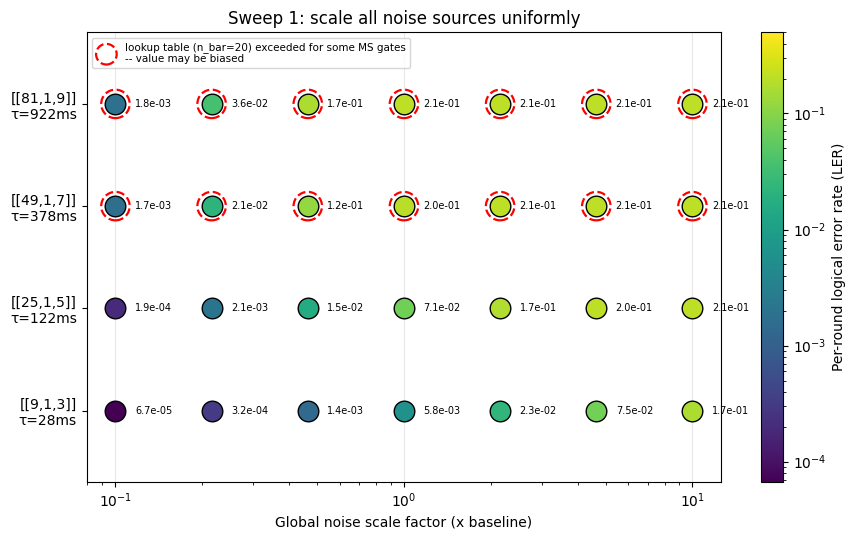

In [9]:
plot_cost_overview(
    results_global,
    x_label='Global noise scale factor (x baseline)',
    title='Sweep 1: scale all noise sources uniformly',
    fname='sweep1_global_scale.png',
)


## Sweep 2: フォノン数の寄与をスワイプする (log)

In [10]:
PHONON_SCALES = np.geomspace(0.01, 10, 7)
results_phonon = run_sweep('phonon_scale', PHONON_SCALES)


  d= 3  phonon_scale=0.01        p_L(round)=1.235e-03  p_L(total)=3.700e-03
  d= 3  phonon_scale=0.03162     p_L(round)=1.258e-03  p_L(total)=3.770e-03
  d= 3  phonon_scale=0.1         p_L(round)=1.365e-03  p_L(total)=4.090e-03
  d= 3  phonon_scale=0.3162      p_L(round)=2.068e-03  p_L(total)=6.190e-03
  d= 3  phonon_scale=1           p_L(round)=5.952e-03  p_L(total)=1.775e-02
  d= 3  phonon_scale=3.162       p_L(round)=4.407e-02  p_L(total)=1.265e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.2724 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.2724 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=23.9677 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=23.9677 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=25.9403 e

  d= 3  phonon_scale=10          p_L(round)=1.658e-01  p_L(total)=4.195e-01  [lookup exceeded]
  d= 5  phonon_scale=0.01        p_L(round)=3.068e-04  p_L(total)=9.200e-04
  d= 5  phonon_scale=0.03162     p_L(round)=3.468e-04  p_L(total)=1.040e-03
  d= 5  phonon_scale=0.1         p_L(round)=7.205e-04  p_L(total)=2.160e-03
  d= 5  phonon_scale=0.3162      p_L(round)=4.679e-03  p_L(total)=1.397e-02
  d= 5  phonon_scale=1           p_L(round)=7.254e-02  p_L(total)=2.022e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.5730 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.5730 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.5611 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.5611 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.7428 e

  d= 5  phonon_scale=3.162       p_L(round)=1.963e-01  p_L(total)=4.809e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1010 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1010 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.4316 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.4316 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=24.0790 e

... (11 outputs left out)

/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.3761 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.3761 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.7031 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.7031 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.7520 e

  d= 9  phonon_scale=3.162       p_L(round)=2.045e-01  p_L(total)=4.966e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.0476 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=22.0476 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=25.2807 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=25.2807 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.7700 e

  d= 9  phonon_scale=10          p_L(round)=2.062e-01  p_L(total)=4.998e-01  [lookup exceeded]


saved: results/ler_evaluation/sweep2_phonon_scale.png


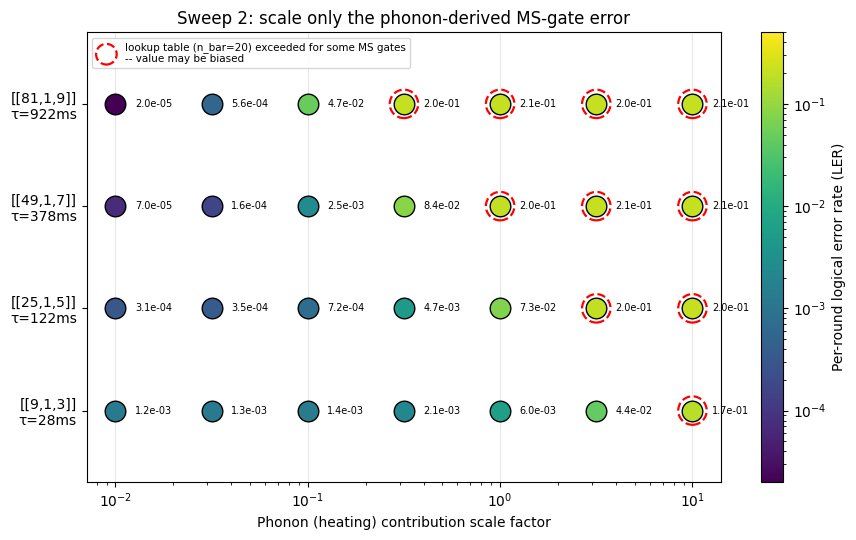

In [11]:
plot_cost_overview(
    results_phonon,
    x_label='Phonon (heating) contribution scale factor',
    title='Sweep 2: scale only the phonon-derived MS-gate error',
    fname='sweep2_phonon_scale.png',
)


## Sweep 3: フォノン数の上限 $n_{max}$ を仮定する

`override_n_bar` で全 MS ゲートの $\bar n$ を実際の compile 結果ではなく
固定値 $n_{max}$ に置き換える。 「ハードウェア改善で heating を
$n_{max}$ 以下に抑えられたら LER はどうなるか」 という設計仮説の評価。

In [12]:
N_MAX_VALUES = np.geomspace(0.05, 20.0, 7)   # lookup table range: [0.01, 20.0]
results_nmax = run_sweep('override_n_bar', N_MAX_VALUES)


  d= 3  override_n_bar=0.05        p_L(round)=1.365e-03  p_L(total)=4.090e-03
  d= 3  override_n_bar=0.1357      p_L(round)=1.352e-03  p_L(total)=4.050e-03
  d= 3  override_n_bar=0.3684      p_L(round)=1.743e-03  p_L(total)=5.220e-03
  d= 3  override_n_bar=1           p_L(round)=2.945e-03  p_L(total)=8.810e-03
  d= 3  override_n_bar=2.714       p_L(round)=1.083e-02  p_L(total)=3.214e-02
  d= 3  override_n_bar=7.368       p_L(round)=7.053e-02  p_L(total)=1.970e-01
  d= 3  override_n_bar=20          p_L(round)=2.005e-01  p_L(total)=4.890e-01
  d= 5  override_n_bar=0.05        p_L(round)=3.101e-04  p_L(total)=9.300e-04
  d= 5  override_n_bar=0.1357      p_L(round)=3.301e-04  p_L(total)=9.900e-04
  d= 5  override_n_bar=0.3684      p_L(round)=4.669e-04  p_L(total)=1.400e-03
  d= 5  override_n_bar=1           p_L(round)=8.574e-04  p_L(total)=2.570e-03
  d= 5  override_n_bar=2.714       p_L(round)=7.567e-03  p_L(total)=2.253e-02
  d= 5  override_n_bar=7.368       p_L(round)=9.462e-02  p_L(tot

saved: results/ler_evaluation/sweep3_n_max.png


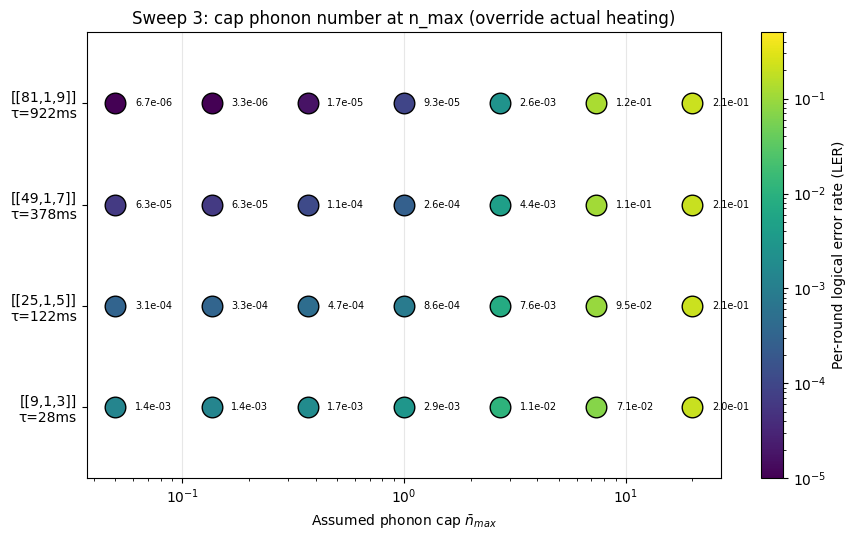

In [13]:
plot_cost_overview(
    results_nmax,
    x_label=r'Assumed phonon cap $\bar{n}_{max}$',
    title='Sweep 3: cap phonon number at n_max (override actual heating)',
    fname='sweep3_n_max.png',
)


## HGP (hypergraph product) 符号

`experiments/generate_hgp_circuits.py` で生成済みの 2 つの符号
(`circuits/hgp_*.py` に保存— 生成済みファイルは QUBIT_COUNT 等の素の
literal のみで numpy/ldpc に依存しないため、 **このセクション自体は
surface code と同じ通常の kernel でそのまま動く**。 GF(2) 線形代数を
使う生成スクリプト側だけが `ldpc` パッケージ
(https://github.com/quantumgizmos/ldpc) に依存し、 `venv/` で実行する
必要がある):

- `hgp_rep3`:      H1=H2=repetition(3) の HGP → **[[13,1,3]]**
  (HGP(repetition, repetition) は通常の surface code に帰着することが
  知られている、構成の正しさ確認用の最小例)
- `hgp_hamming74`: H1=H2=Hamming(7,4) の HGP → **[[58,16,>=3]]**
  (genuinely LDPC な最初の例。 $k=16$ だが、 `recompile_multi_round` が
  単一 observable しか張れないため **代表 1 個の logical Z だけ** を見る
  ことに注意)

アーキテクチャは surface code と同じ `simple_mlm` (single-LIZ) のまま。
HGP のスタビライザは surface code と違い non-local (sector A/B 間で離れた
qubit を繋ぐ) なので、 shuttle が大幅に増え **code cycle time $C$ が
大きく伸びる** ことを期待して観察する
(実測: hgp_rep3 C=69ms (vs d=3 surface code 28ms)、 hgp_hamming74
C=1108ms (vs d=9 surface code 922ms、 qubit 数は 59 < 82 なのに逆転) —
non-locality コストが明確に出ている)。

forward circuit を毎ラウンド再利用する (reverse 不要 — `recompile_multi_round`
は `(basis, frozenset(data_qubits))` の identity で detector を張るため
順序に依存しない)。 `hgp_hamming74` (59 qubit、 非局所性大) の compile は
実測 1 round あたり約 9 秒 (3 round で約 30 秒) で、 想定より軽い。

In [14]:
HGP_CODES = ['hgp_rep3', 'hgp_hamming74']


def compile_css_code(name: str, rounds: int = ROUNDS) -> dict:
    """汎用 CSS 符号コンパイル関数 (circuits/<name>.py が QUBIT_COUNT /
    DATA_QUBITS / ANCILLA_QUBITS / LOGICAL_Z_OPERATORS / D_LOWER_BOUND を
    持っていれば、 HGP でも BB でも同じロジックで使える)。

    surface code と異なり reverse circuit は使わず、 同じ forward circuit を
    毎ラウンド再利用する (`recompile_multi_round` は stabilizer identity =
    (basis, frozenset(data_qubits)) でマッチするため、 順序が同じでも問題ない)。

    observable には `LOGICAL_Z_OPERATORS[0]` (k 個ある logical のうち代表 1 個)
    だけ使う — `recompile_multi_round` が単一 OBSERVABLE_INCLUDE(0) しか
    張れないため、 k>1 の符号でも代表 1 個分の LER を見る
    (複数 observable 対応は今後の拡張)。

    `D_IS_EXACT` が True (BB code の既知 distance など) なら d をそのまま
    表示し、 False/未定義 (HGP の構成的下界など) なら ">=" を付けて表示する。
    """
    mod = __import__(name)
    half = (len(mod.DATA_QUBITS) + 1) // 2
    mem_cap = max(20, half + len(mod.ANCILLA_QUBITS) + 4)
    arch = QCCDArchitecture.simple_mlm(liz_capacity=4, memory_capacity=mem_cap)
    placement = placement_greedy_alt(mod.DATA_QUBITS, mod.ANCILLA_QUBITS, mod)

    results = []
    zone_contents = None
    for r in range(1, rounds + 1):
        result = _compile_round(name, placement, arch, initial_zone_contents=zone_contents)
        results.append(result)
        placement, zone_contents = result.final_placement, result.final_zone_contents

    circuit = recompile_multi_round(results, observable_column=mod.LOGICAL_Z_OPERATORS[0])

    phonon_gates = []
    for r in results:
        phonon_gates.extend((r.phonon_data or {}).get('at_gates', []))

    est = ParallelEstimator()
    cycle_times_ms = [est.estimate(r.timesteps).total_time / 1000 for r in results]

    d_is_exact = getattr(mod, 'D_IS_EXACT', False)
    d_label = str(mod.D_LOWER_BOUND) if d_is_exact else f'>={mod.D_LOWER_BOUND}'

    return {
        'n': len(mod.DATA_QUBITS), 'k': len(mod.LOGICAL_Z_OPERATORS),
        'd': d_label,
        'Q': len(mod.DATA_QUBITS) + len(mod.ANCILLA_QUBITS),
        'n_ancilla': len(mod.ANCILLA_QUBITS),
        'circuit': circuit,
        'compile_results': results,
        'phonon_gates': phonon_gates,
        'C_ms': sum(cycle_times_ms) / len(cycle_times_ms),
    }


In [15]:
print(f'Compiling HGP codes {HGP_CODES} ({ROUNDS} rounds each)...')
for name in HGP_CODES:
    print(f'  {name} ...', end=' ', flush=True)
    CODE_CACHE[name] = compile_css_code(name, rounds=ROUNDS)
    info = CODE_CACHE[name]
    print(f"[[{info['n']},{info['k']},{info['d']}]]  Q={info['Q']}  "
          f"(data={info['n']} + ancilla={info['n_ancilla']})  "
          f"C={info['C_ms']:.2f} ms  MS gates/round={len(info['phonon_gates']) // ROUNDS}")
print('Done.')


Compiling HGP codes ['hgp_rep3', 'hgp_hamming74'] (3 rounds each)...
  hgp_rep3 ... [[13,1,>=3]]  Q=14  (data=13 + ancilla=1)  C=69.06 ms  MS gates/round=40
  hgp_hamming74 ... [[58,16,>=3]]  Q=59  (data=58 + ancilla=1)  C=1108.03 ms  MS gates/round=240
Done.


### Sweep 1 (HGP): ノイズ全体を定数倍する

In [16]:
results_global_hgp = run_sweep('global_scale', GLOBAL_SCALES, distances=HGP_CODES)

  d=hgp_rep3  global_scale=0.1         p_L(round)=1.091e-03  p_L(total)=3.270e-03
  d=hgp_rep3  global_scale=0.2154      p_L(round)=4.477e-03  p_L(total)=1.337e-02
  d=hgp_rep3  global_scale=0.4642      p_L(round)=1.849e-02  p_L(total)=5.446e-02
  d=hgp_rep3  global_scale=1           p_L(round)=6.365e-02  p_L(total)=1.790e-01
  d=hgp_rep3  global_scale=2.154       p_L(round)=1.515e-01  p_L(total)=3.891e-01
  d=hgp_rep3  global_scale=4.642       p_L(round)=2.023e-01  p_L(total)=4.924e-01
  d=hgp_rep3  global_scale=10          p_L(round)=2.056e-01  p_L(total)=4.986e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.5352 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.5352 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.5653 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.5653 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.0407 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  global_scale=0.1         p_L(round)=5.684e-02  p_L(total)=1.610e-01  [lookup exceeded]
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  global_scale=0.2154      p_L(round)=1.274e-01  p_L(total)=3.355e-01  [lookup exceeded]
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  global_scale=0.4642      p_L(round)=1.823e-01  p_L(total)=4.532e-01  [lookup exceeded]
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  global_scale=1           p_L(round)=2.100e-01  p_L(total)=5.070e-01  [lookup exceeded]
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  global_scale=2.154       p_L(round)=2.116e-01  p_L(total)=5.100e-01  [lookup exceeded]
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  

saved: results/ler_evaluation/sweep1_global_scale_hgp.png


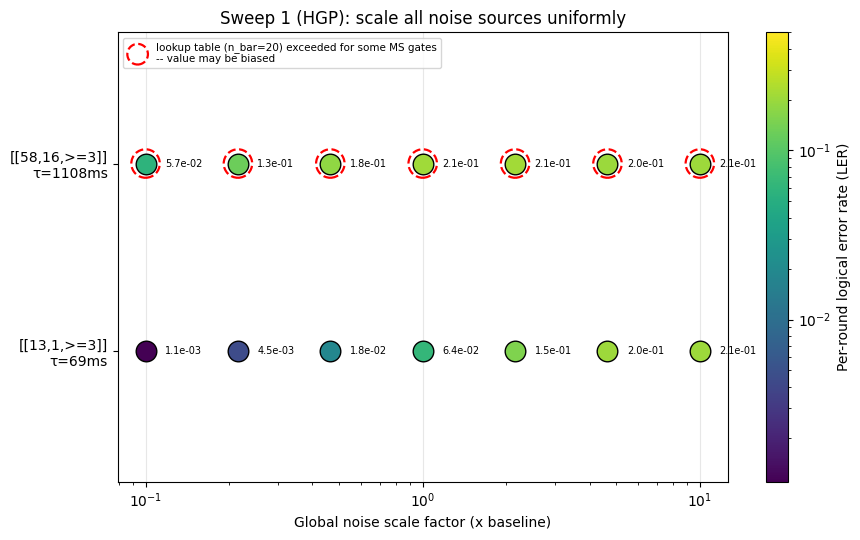

In [17]:
plot_cost_overview(
    results_global_hgp,
    x_label='Global noise scale factor (x baseline)',
    title='Sweep 1 (HGP): scale all noise sources uniformly',
    fname='sweep1_global_scale_hgp.png',
)


### Sweep 2 (HGP): フォノン数の寄与をスワイプする (log)

In [18]:
results_phonon_hgp = run_sweep('phonon_scale', PHONON_SCALES, distances=HGP_CODES)


  d=hgp_rep3  phonon_scale=0.01        p_L(round)=1.569e-03  p_L(total)=4.700e-03
  d=hgp_rep3  phonon_scale=0.03162     p_L(round)=1.770e-03  p_L(total)=5.300e-03
  d=hgp_rep3  phonon_scale=0.1         p_L(round)=3.073e-03  p_L(total)=9.190e-03
  d=hgp_rep3  phonon_scale=0.3162      p_L(round)=8.892e-03  p_L(total)=2.644e-02
  d=hgp_rep3  phonon_scale=1           p_L(round)=6.392e-02  p_L(total)=1.798e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1477 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1477 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.0230 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.0230 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.8692 e

  d=hgp_rep3  phonon_scale=3.162       p_L(round)=1.899e-01  p_L(total)=4.684e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.8644 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.8644 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=23.6924 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=23.6924 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=24.1310 e

  d=hgp_rep3  phonon_scale=10          p_L(round)=1.986e-01  p_L(total)=4.854e-01  [lookup exceeded]
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  phonon_scale=0.01        p_L(round)=1.129e-02  p_L(total)=3.350e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  phonon_scale=0.03162     p_L(round)=5.562e-02  p_L(total)=1.578e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.0093 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.0093 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1122 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1122 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1597 e

... (5 outputs left out)

/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.0632 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.0632 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.3676 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=22.3676 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=24.2980 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  phonon_scale=3.162       p_L(round)=2.045e-01  p_L(total)=4.965e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.7264 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.7264 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=23.9594 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=23.9594 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=26.3560 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  phonon_scale=10          p_L(round)=2.076e-01  p_L(total)=5.025e-01  [lookup exceeded]


saved: results/ler_evaluation/sweep2_phonon_scale_hgp.png


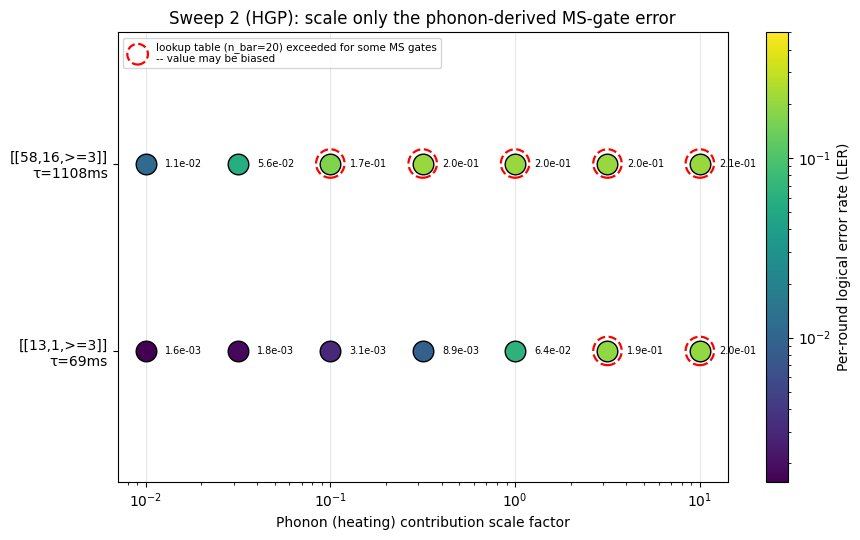

In [19]:
plot_cost_overview(
    results_phonon_hgp,
    x_label='Phonon (heating) contribution scale factor',
    title='Sweep 2 (HGP): scale only the phonon-derived MS-gate error',
    fname='sweep2_phonon_scale_hgp.png',
)


### Sweep 3 (HGP): フォノン数の上限 $n_{max}$ を仮定する

In [20]:
results_nmax_hgp = run_sweep('override_n_bar', N_MAX_VALUES, distances=HGP_CODES)


  d=hgp_rep3  override_n_bar=0.05        p_L(round)=1.626e-03  p_L(total)=4.870e-03
  d=hgp_rep3  override_n_bar=0.1357      p_L(round)=1.542e-03  p_L(total)=4.620e-03
  d=hgp_rep3  override_n_bar=0.3684      p_L(round)=2.309e-03  p_L(total)=6.910e-03
  d=hgp_rep3  override_n_bar=1           p_L(round)=3.737e-03  p_L(total)=1.117e-02
  d=hgp_rep3  override_n_bar=2.714       p_L(round)=1.304e-02  p_L(total)=3.861e-02
  d=hgp_rep3  override_n_bar=7.368       p_L(round)=8.396e-02  p_L(total)=2.313e-01
  d=hgp_rep3  override_n_bar=20          p_L(round)=2.029e-01  p_L(total)=4.936e-01
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  override_n_bar=0.05        p_L(round)=3.848e-03  p_L(total)=1.150e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=hgp_hamming74  override_n_bar=0.1357      p_L(round)=5.362e-03  p_L(total)=1.600e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]


saved: results/ler_evaluation/sweep3_n_max_hgp.png


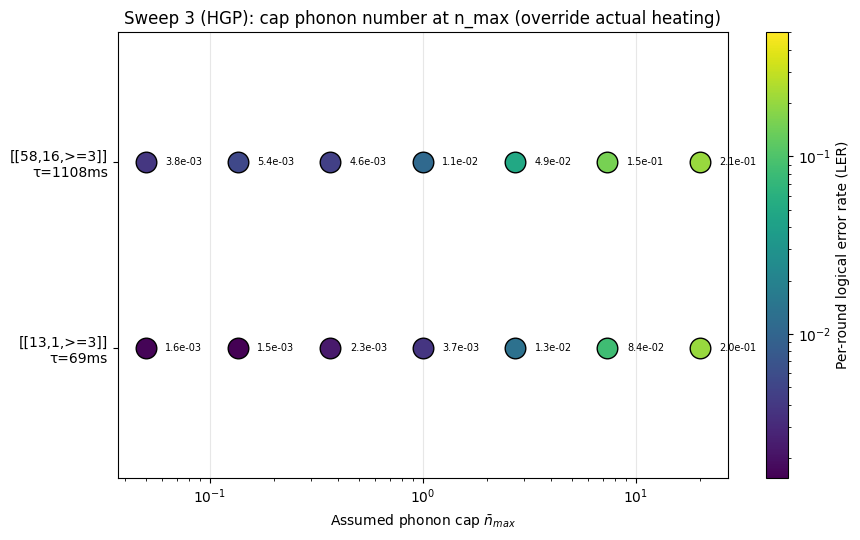

In [21]:
plot_cost_overview(
    results_nmax_hgp,
    x_label=r'Assumed phonon cap $\bar{n}_{max}$',
    title='Sweep 3 (HGP): cap phonon number at n_max (override actual heating)',
    fname='sweep3_n_max_hgp.png',
)


## BB (bivariate bicycle) 符号

`experiments/generate_bb_circuits.py` で生成済み (Bravyi et al. 2024,
arXiv:2308.07915 の "gross code" 系列、 A=x^3+y+y^2, B=y^3+x+x^2 共通、
lattice サイズだけ変える)。 構成は
[qiskit-community/qcode-discovery](https://github.com/qiskit-community/qcode-discovery)
が使っている `qldpc.codes.BBCode` に委譲 (HGP の独自実装と違い、 BB は
qldpc を直接使う)。

**注意**: `qldpc` は numpy>=2.2 / stim dev-build を要求するため、 HGP 用の
`venv/` とも別の専用 `venv_bb/` (Python 3.10+) が必要
(`./venv_bb/bin/python experiments/generate_bb_circuits.py`)。
生成済み `circuits/bb_*.py` 自体は literal のみで依存無し — **このセクションは
通常の kernel でそのまま動く**。

- `bb_72_12_6`:   (ell,m)=(6,6)  → **[[72,12,6]]** (既知の最小良好 BB code)
- `bb_144_12_12`: (ell,m)=(12,6) → **[[144,12,12]]** (= "gross code"、 本家)

distance はどちらも文献値 (MILP 確認済み、 exact) — `D_IS_EXACT=True` として
埋め込んでいるので `compile_css_code` が ">=" 無しでそのまま表示する。

HGP よりさらに stabilizer が稠密 (全 stabilizer 重み 6、 X/Z 各 n/2 個) かつ
non-local なため、 cycle time $C$ はさらに伸びる見込み。 デコードも
`hgp_hamming74` と同様 MWPM が原理的に通らず BP+OSD フォールバックになる
可能性が高い (既存の `simulate_p_L` がそのまま自動対応する)。

**compile 時間の実測 (1 round)**: `bb_72_12_6` (73 qubit) 25.5 秒、
`bb_144_12_12` (145 qubit) 261.8 秒 (約 4.4 分)。 3 round 分のキャッシュ構築
には `bb_144_12_12` だけで 約 13 分かかる見込み — 他のセルより明確に時間が
かかるので、 実行中は気長に待つこと。

In [40]:
BB_CODES = ['bb_72_12_6']  # 'bb_144_12_12'

print(f'Compiling BB codes {BB_CODES} ({ROUNDS} rounds each)...')
for name in BB_CODES:
    print(f'  {name} ...', end=' ', flush=True)
    CODE_CACHE[name] = compile_css_code(name, rounds=ROUNDS)
    info = CODE_CACHE[name]
    print(f"[[{info['n']},{info['k']},{info['d']}]]  Q={info['Q']}  "
          f"(data={info['n']} + ancilla={info['n_ancilla']})  "
          f"C={info['C_ms']:.2f} ms  MS gates/round={len(info['phonon_gates']) // ROUNDS}")
print('Done.')


Compiling BB codes ['bb_72_12_6'] (3 rounds each)...
  bb_72_12_6 ... [[72,12,6]]  Q=73  (data=72 + ancilla=1)  C=3128.00 ms  MS gates/round=432
Done.


### Sweep 1 (BB): ノイズ全体を定数倍する
- 重いので一旦skip

In [84]:
# results_global_bb = run_sweep('global_scale', GLOBAL_SCALES, distances=BB_CODES)

In [85]:
# plot_cost_overview(
#     results_global_bb,
#     x_label='Global noise scale factor (x baseline)',
#     title='Sweep 1 (BB): scale all noise sources uniformly',
#     fname='sweep1_global_scale_bb.png',
# )

### Sweep 2 (BB): フォノン数の寄与をスワイプする (log)

In [79]:
results_phonon_bb = run_sweep('phonon_scale', PHONON_SCALES, distances=BB_CODES)


    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=0.01        p_L(round)=1.360e-01  p_L(total)=3.550e-01
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=0.03162     p_L(round)=2.043e-01  p_L(total)=4.963e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1142 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1142 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.2968 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.2968 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1884 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=0.1         p_L(round)=2.095e-01  p_L(total)=5.060e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.3435 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.3435 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.1347 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.1347 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.3306 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=0.3162      p_L(round)=2.063e-01  p_L(total)=5.000e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.3923 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.3923 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.3035 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.3035 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.7551 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=1           p_L(round)=2.037e-01  p_L(total)=4.950e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1814 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1814 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.6867 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.6867 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.8828 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=3.162       p_L(round)=2.068e-01  p_L(total)=5.010e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.4116 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=22.4116 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=24.9660 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=24.9660 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=30.4597 e

    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  phonon_scale=10          p_L(round)=2.088e-01  p_L(total)=5.048e-01  [lookup exceeded]


saved: results/ler_evaluation/sweep2_phonon_scale_bb.png


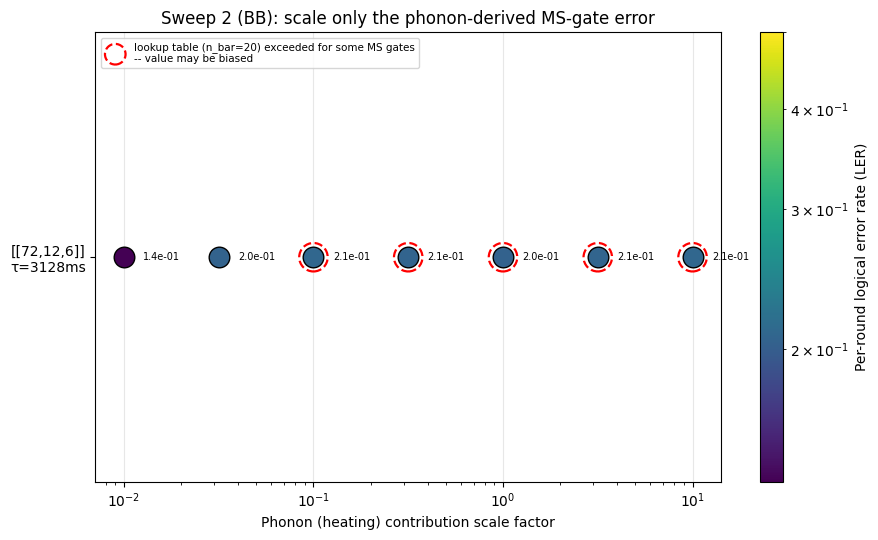

In [80]:
plot_cost_overview(
    results_phonon_bb,
    x_label='Phonon (heating) contribution scale factor',
    title='Sweep 2 (BB): scale only the phonon-derived MS-gate error',
    fname='sweep2_phonon_scale_bb.png',
)


### Sweep 3 (BB): フォノン数の上限 $n_{max}$ を仮定する

In [62]:
results_nmax_bb = run_sweep('override_n_bar', N_MAX_VALUES, distances=BB_CODES)


    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  override_n_bar=0.05        p_L(round)=9.847e-03  p_L(total)=2.925e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  override_n_bar=0.1357      p_L(round)=8.150e-03  p_L(total)=2.425e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  override_n_bar=0.3684      p_L(round)=1.704e-02  p_L(total)=5.025e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  override_n_bar=1           p_L(round)=2.865e-02  p_L(total)=8.350e-02
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  override_n_bar=2.714       p_L(round)=1.319e-01  p_L(total)=3.458e-01
    [MWPM unsupported for this code -> BP+OSD fallback, shots 100000 -> 4000]
  d=bb_72_12_6  override_n_bar=7.368       p_L(round)=2.079e-01  p_L(total)=5.030e-01
    [MWPM unsupp

saved: results/ler_evaluation/sweep3_n_max_bb.png


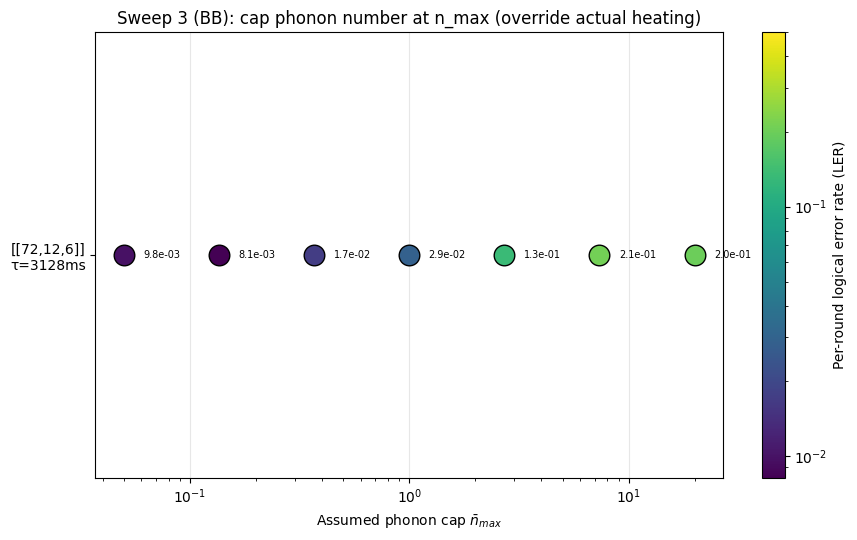

In [63]:
plot_cost_overview(
    results_nmax_bb,
    x_label=r'Assumed phonon cap $\bar{n}_{max}$',
    title='Sweep 3 (BB): cap phonon number at n_max (override actual heating)',
    fname='sweep3_n_max_bb.png',
)


## Many-hypercube 符号

Hayato Goto, "Many-hypercube codes: High-rate quantum error-correcting
codes for high-performance fault-tolerant quantum computing"
(arXiv:2403.16054)。 $[[6,4,2]]$ 量子誤り検出符号の level-2 concatenation。

`experiments/code_params/many_hypercube_l2_row_compact.json` に Hx, Hz,
**logical_Z も含めて** 既に dense 0/1 行列で用意されている (HGP/BB と違い
GF(2) 構成も logical operator 計算も不要 — そのまま読み込むだけ)。
`experiments/generate_many_hypercube_circuits.py` が
`circuits/many_hypercube_l2.py` を生成 (依存は numpy + 既存の `ldpc` のみ、
専用 venv 不要)。

- `many_hypercube_l2`: **[[36,16,4]]**。 $d=4$ は $[[6,4,2]]$ ($d_1=2$) の
  level-2 concatenation による構成的事実 ($d = d_1^{level} = 2^2$、
  concatenated code の distance 倍増則、 decoder に依らない) —
  source data の logical_Z 16 本全てが重み 4 であることでも独立に確認済み
  (`D_IS_EXACT=True`)。

stabilizer は level-1 (重み 6) と level-2 (重み 12、 2 つの level-1 block
を跨ぐ) の混在。 36 qubit (+ancilla=37) と小さいため compile は高速
(実測 1.4 秒/round)。 **デコーダについて**: HGP/BB と違いこの符号は実測で
**MWPM (pymatching) がそのまま通る** (weight-12 stabilizer はあるが
n=36 と小さいため decompose に失敗しない) — `simulate_p_L` は自動で
判定するので特別な対応は不要だが、 BP+OSD フォールバックは発生しない
(= SHOTS をフルで使える、 高速)。

In [24]:
MANY_HYPERCUBE_CODES = ['many_hypercube_l2']

print(f'Compiling many-hypercube codes {MANY_HYPERCUBE_CODES} ({ROUNDS} rounds each)...')
for name in MANY_HYPERCUBE_CODES:
    print(f'  {name} ...', end=' ', flush=True)
    CODE_CACHE[name] = compile_css_code(name, rounds=ROUNDS)
    info = CODE_CACHE[name]
    print(f"[[{info['n']},{info['k']},{info['d']}]]  Q={info['Q']}  "
          f"(data={info['n']} + ancilla={info['n_ancilla']})  "
          f"C={info['C_ms']:.2f} ms  MS gates/round={len(info['phonon_gates']) // ROUNDS}")
print('Done.')


Compiling many-hypercube codes ['many_hypercube_l2'] (3 rounds each)...
  many_hypercube_l2 ... [[36,16,4]]  Q=37  (data=36 + ancilla=1)  C=695.09 ms  MS gates/round=168
Done.


### Sweep 1 (Many-hypercube): ノイズ全体を定数倍する

In [25]:
results_global_mhc = run_sweep('global_scale', GLOBAL_SCALES, distances=MANY_HYPERCUBE_CODES)


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1890 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1890 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.1190 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.1190 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.5066 e

  d=many_hypercube_l2  global_scale=0.1         p_L(round)=1.077e-01  p_L(total)=2.896e-01  [lookup exceeded]
  d=many_hypercube_l2  global_scale=0.2154      p_L(round)=1.876e-01  p_L(total)=4.637e-01  [lookup exceeded]
  d=many_hypercube_l2  global_scale=0.4642      p_L(round)=2.059e-01  p_L(total)=4.993e-01  [lookup exceeded]
  d=many_hypercube_l2  global_scale=1           p_L(round)=2.054e-01  p_L(total)=4.983e-01  [lookup exceeded]
  d=many_hypercube_l2  global_scale=2.154       p_L(round)=2.056e-01  p_L(total)=4.987e-01  [lookup exceeded]
  d=many_hypercube_l2  global_scale=4.642       p_L(round)=2.052e-01  p_L(total)=4.980e-01  [lookup exceeded]
  d=many_hypercube_l2  global_scale=10          p_L(round)=2.060e-01  p_L(total)=4.995e-01  [lookup exceeded]


saved: results/ler_evaluation/sweep1_global_scale_mhc.png


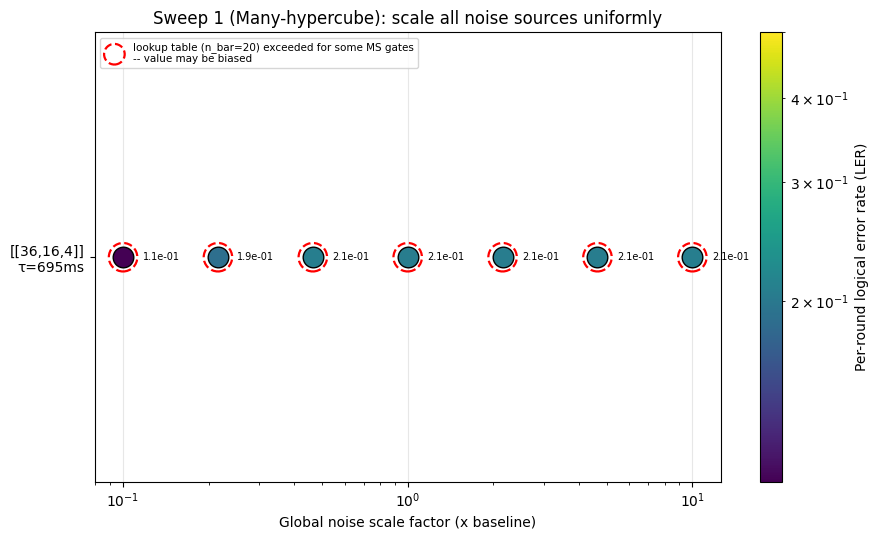

In [26]:
plot_cost_overview(
    results_global_mhc,
    x_label='Global noise scale factor (x baseline)',
    title='Sweep 1 (Many-hypercube): scale all noise sources uniformly',
    fname='sweep1_global_scale_mhc.png',
)


### Sweep 2 (Many-hypercube): フォノン数の寄与をスワイプする (log)

In [27]:
results_phonon_mhc = run_sweep('phonon_scale', PHONON_SCALES, distances=MANY_HYPERCUBE_CODES)


  d=many_hypercube_l2  phonon_scale=0.01        p_L(round)=2.208e-02  p_L(total)=6.480e-02
  d=many_hypercube_l2  phonon_scale=0.03162     p_L(round)=7.303e-02  p_L(total)=2.035e-01
  d=many_hypercube_l2  phonon_scale=0.1         p_L(round)=1.970e-01  p_L(total)=4.822e-01


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.0138 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.0138 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.0923 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.0923 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.4241 e

  d=many_hypercube_l2  phonon_scale=0.3162      p_L(round)=2.069e-01  p_L(total)=5.012e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=20.1890 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=20.1890 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.1190 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.1190 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.5066 e

  d=many_hypercube_l2  phonon_scale=1           p_L(round)=2.073e-01  p_L(total)=5.020e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=21.1254 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=21.1254 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=23.3995 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=23.3995 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=27.3789 e

  d=many_hypercube_l2  phonon_scale=3.162       p_L(round)=2.082e-01  p_L(total)=5.035e-01  [lookup exceeded]


/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=22.5220 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=22.5220 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=24.9896 exceeds lookup table max 20.0; clipping to 20.0
  n_bar_used = lookup.select_n_bar(n_input, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/src/pauli_lookup.py:126: RuntimeWarning: n_bar=24.9896 exceeds lookup table max 20.0; clipping to 20.0
  selected_n = self.select_n_bar(n_bar, mode=mode)
/Users/parton/KEIO-UCL/MSTakahashi/qccd_time_simulator/experiments/exp_noise_injection.py:166: RuntimeWarning: n_bar=27.9085 e

  d=many_hypercube_l2  phonon_scale=10          p_L(round)=2.065e-01  p_L(total)=5.004e-01  [lookup exceeded]


saved: results/ler_evaluation/sweep2_phonon_scale_mhc.png


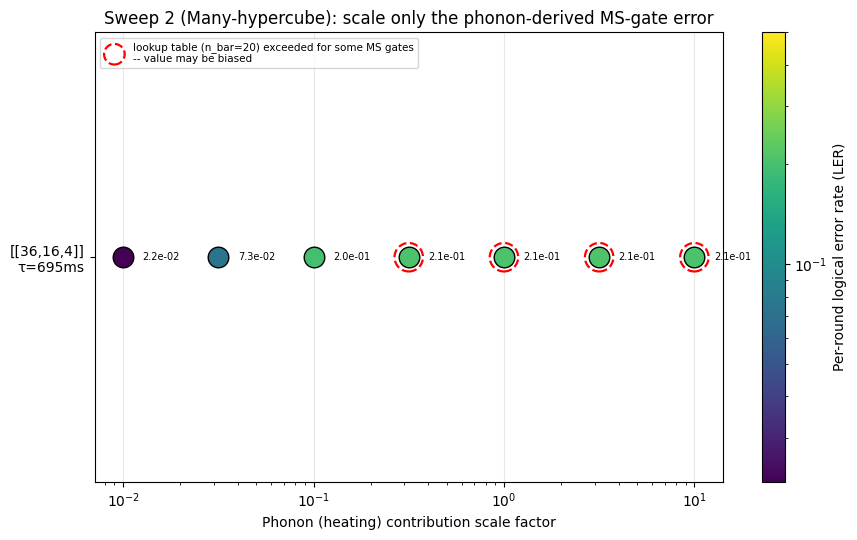

In [28]:
plot_cost_overview(
    results_phonon_mhc,
    x_label='Phonon (heating) contribution scale factor',
    title='Sweep 2 (Many-hypercube): scale only the phonon-derived MS-gate error',
    fname='sweep2_phonon_scale_mhc.png',
)


### Sweep 3 (Many-hypercube): フォノン数の上限 $n_{max}$ を仮定する

In [29]:
results_nmax_mhc = run_sweep('override_n_bar', N_MAX_VALUES, distances=MANY_HYPERCUBE_CODES)


  d=many_hypercube_l2  override_n_bar=0.05        p_L(round)=1.354e-02  p_L(total)=4.007e-02
  d=many_hypercube_l2  override_n_bar=0.1357      p_L(round)=1.320e-02  p_L(total)=3.909e-02
  d=many_hypercube_l2  override_n_bar=0.3684      p_L(round)=1.762e-02  p_L(total)=5.193e-02
  d=many_hypercube_l2  override_n_bar=1           p_L(round)=2.778e-02  p_L(total)=8.105e-02
  d=many_hypercube_l2  override_n_bar=2.714       p_L(round)=9.008e-02  p_L(total)=2.466e-01
  d=many_hypercube_l2  override_n_bar=7.368       p_L(round)=2.041e-01  p_L(total)=4.957e-01
  d=many_hypercube_l2  override_n_bar=20          p_L(round)=2.059e-01  p_L(total)=4.992e-01


saved: results/ler_evaluation/sweep3_n_max_mhc.png


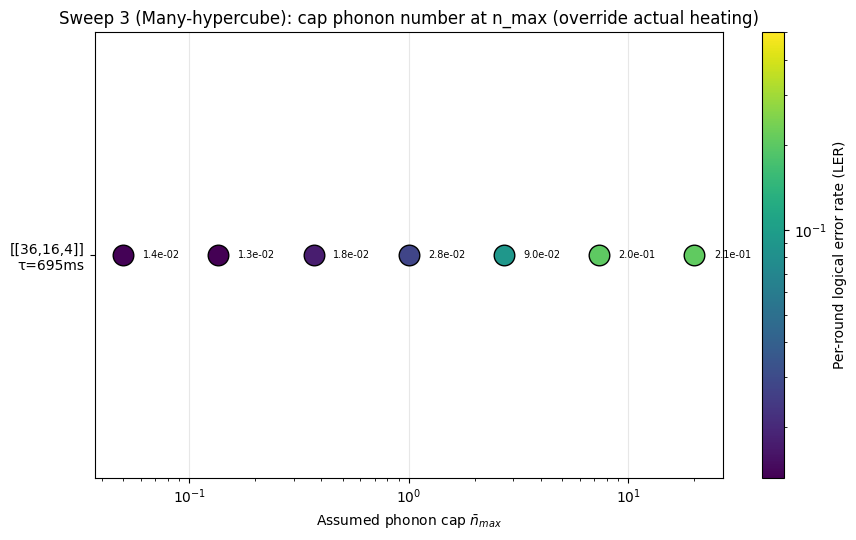

In [30]:
plot_cost_overview(
    results_nmax_mhc,
    x_label=r'Assumed phonon cap $\bar{n}_{max}$',
    title='Sweep 3 (Many-hypercube): cap phonon number at n_max (override actual heating)',
    fname='sweep3_n_max_mhc.png',
)


## 全符号まとめプロット

これまでの符号 (表面符号 / HGP / BB / Many-hypercube) を符号ファミリーごとに
分けず 1 枚にまとめる。 縦軸はカテゴリ行ではなく実際の $n$ (log scale) — $n$
が近い符号同士でも区別できるよう、 点の **マーカー形状を符号ごとに** 変える
(色は従来通り 1-round LER)。 点数が多くなるため個々の LER 数値テキストは
省略し、 色 + colorbar で読む。

In [74]:
# _COMBINED_MARKERS = ['o', 's', '^', 'v', 'D', 'p', '*', 'o', 'h', '<', '>', 'P']
_COMBINED_MARKERS = ['o', 's', 'o', 'v', 'o', 'p', '*', 'o', 'h', '<', '>', 'P']
def plot_cost_overview_combined(results: dict, x_label: str, title: str, fname: str,
                                x_log: bool = True, y_log: bool = True,
                                y_metric: str = 'n') -> None:
    """これまでの全符号を 1 枚にまとめた図。 縦軸は `y_metric` で選ぶ:
      - 'n' (default): 必要 qubit 数 (log scale、 各符号の n に目盛)
      - 'rate':         coding rate k/n (各符号の k/n に目盛)
    横軸 = ノイズパラメータ、 色 = 1-round LER、 マーカー形状 = 符号ごとに
    変える (値が近い符号でも区別できる)。 各点には LER 値を科学的記数法で
    テキスト注記する。 lookup table 超過点は赤い破線の丸で強調する。
    """
    codes = sorted(results.items(), key=lambda kv: kv[1][0]['n'])
    all_ler = [max(p['p_L_round'], 1e-5) for _, pts in codes for p in pts]
    norm = LogNorm(vmin=min(all_ler), vmax=max(max(all_ler), 0.5))

    if y_metric == 'rate':
        y_of = lambda pt0: pt0['k'] / pt0['n']
        ylabel = 'Coding rate $k/n$'
        fmt_tick = lambda v: f'{v:.3f}'
    else:
        y_of = lambda pt0: pt0['n']
        ylabel = 'Required qubits $n$'
        fmt_tick = lambda v: str(int(v))

    fig, ax = plt.subplots(figsize=(11, 7))
    sc = None
    for marker, (name, pts) in zip(_COMBINED_MARKERS, codes):
        y_val = y_of(pts[0])
        xs = [p['x'] for p in pts]
        ys = [y_val] * len(pts)
        colors = [max(p['p_L_round'], 1e-5) for p in pts]
        label = f"[[{pts[0]['n']},{pts[0]['k']},{pts[0]['d']}]] ({name})"
        sc = ax.scatter(xs, ys, c=colors, cmap='viridis', norm=norm, marker=marker,
                       s=140, edgecolors='black', linewidths=1.0, zorder=3, label=label)
        for p in pts:
            ax.annotate(f"{p['p_L_round']:.1e}",
                       (p['x'], y_val), textcoords='offset points', xytext=(10, 6),
                       fontsize=6.5, va='center')
            if p['exceeded']:
                ax.scatter([p['x']], [y_val], s=280, facecolors='none',
                         edgecolors='red', linewidths=1.6, linestyle='--', zorder=4)

    ax.set_xlabel(x_label)
    ax.set_ylabel(ylabel)
    if x_log:
        ax.set_xscale('log')
    if y_log:
        ax.set_yscale('log')
    y_values = sorted({y_of(pts[0]) for _, pts in codes})
    ax.set_yticks(y_values)
    ax.set_yticklabels([fmt_tick(v) for v in y_values])
    ax.minorticks_off()
    ax.grid(alpha=0.3, which='both')
    ax.set_title(title)

    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('Per-round logical error rate (LER)')

    handles, labels = ax.get_legend_handles_labels()
    if any(p['exceeded'] for _, pts in codes for p in pts):
        proxy = ax.scatter([], [], s=140, facecolors='none', edgecolors='red',
                          linewidths=1.6, linestyle='--',
                          label=f'lookup table (n_bar={PAULI_LOOKUP.n_bar_range[1]:g}) exceeded')
        handles.append(proxy)
    ax.legend(handles=handles, fontsize=7.5, loc='upper center',
             bbox_to_anchor=(0.5, -0.13), ncol=3, title='Code [[n,k,d]]')

    fig.tight_layout()
    outdir = REPO / 'results' / 'ler_evaluation'
    outdir.mkdir(parents=True, exist_ok=True)
    fig.savefig(outdir / fname, dpi=150, bbox_inches='tight')
    print(f'saved: {(outdir / fname).relative_to(REPO)}')
    plt.show()


### Sweep 1 (全符号): ノイズ全体を定数倍する

In [35]:
results_global_all = {**results_global, **results_global_hgp, **results_global_bb, **results_global_mhc}
plot_cost_overview_combined(
    results_global_all,
    x_label='Global noise scale factor (x baseline)',
    title='Sweep 1 (All codes): scale all noise sources uniformly',
    fname='sweep1_global_scale_all.png',
)


NameError: name 'results_global_bb' is not defined

### Sweep 2 (全符号): フォノン数の寄与をスワイプする (log)

saved: results/ler_evaluation/sweep2_phonon_scale_all.png


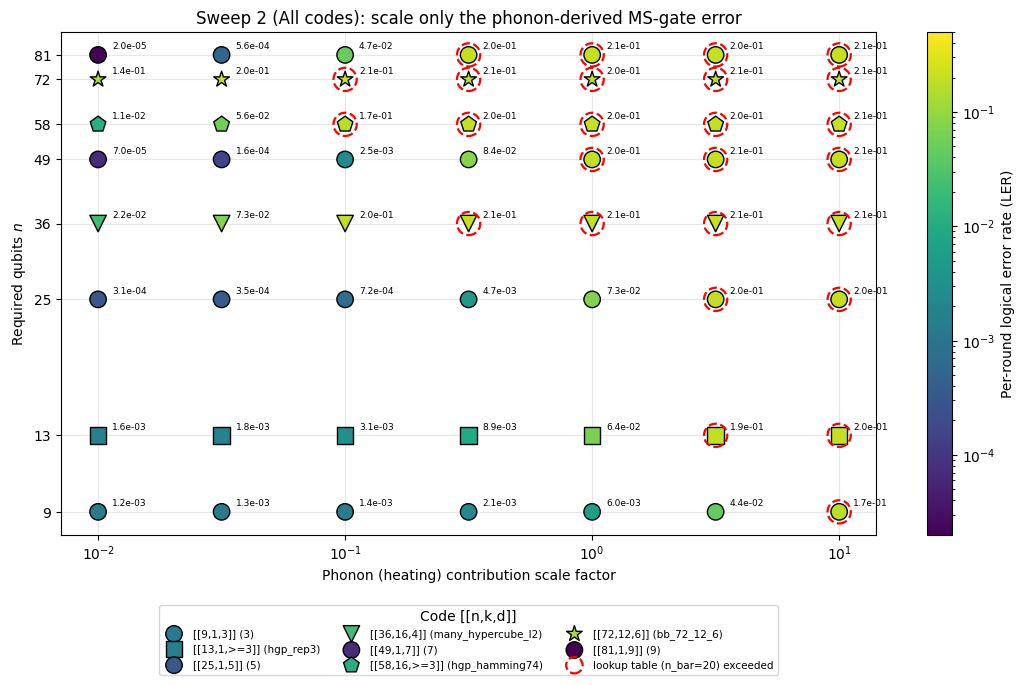

In [81]:
results_phonon_all = {**results_phonon, **results_phonon_hgp, **results_phonon_mhc,  **results_phonon_bb} # **results_phonon_bb
plot_cost_overview_combined(
    results_phonon_all,
    x_label='Phonon (heating) contribution scale factor',
    title='Sweep 2 (All codes): scale only the phonon-derived MS-gate error',
    fname='sweep2_phonon_scale_all.png',
)


### Sweep 3 (全符号): フォノン数の上限 $n_{max}$ を仮定する

saved: results/ler_evaluation/sweep3_n_max_all.png


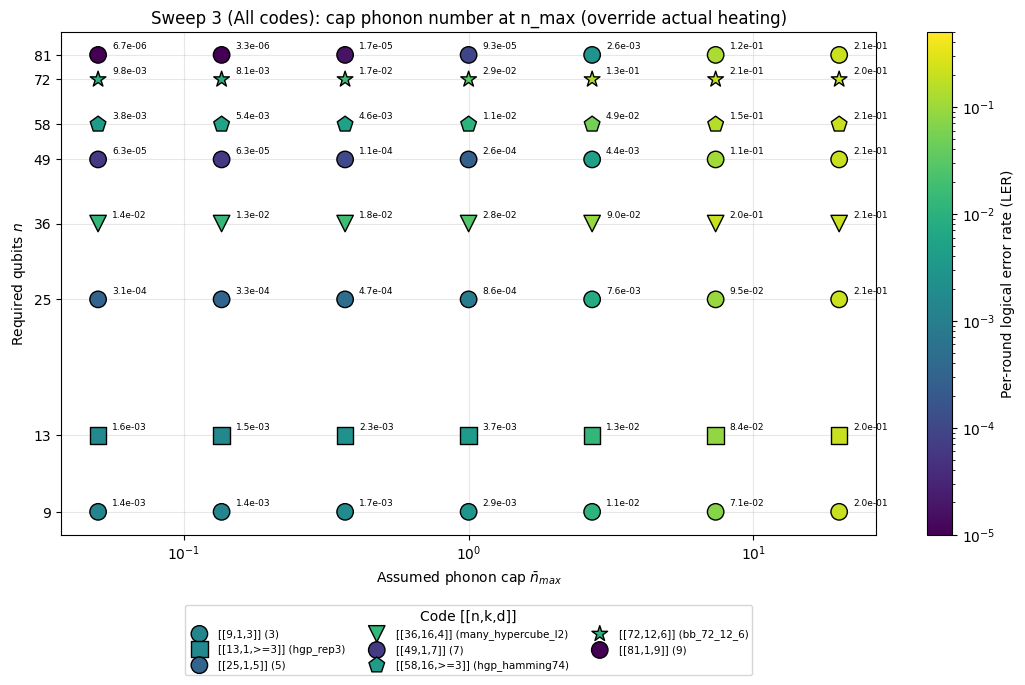

In [75]:
results_nmax_all = {**results_nmax, **results_nmax_hgp, **results_nmax_mhc, **results_nmax_bb} # **results_nmax_bb
plot_cost_overview_combined(
    results_nmax_all,
    x_label=r'Assumed phonon cap $\bar{n}_{max}$',
    title='Sweep 3 (All codes): cap phonon number at n_max (override actual heating)',
    fname='sweep3_n_max_all.png',
)


### Sweep 1 (全符号, coding rate): ノイズ全体を定数倍する

In [86]:
# plot_cost_overview_combined(
#     results_global_all,
#     x_label='Global noise scale factor (x baseline)',
#     title='Sweep 1 (All codes, coding rate): scale all noise sources uniformly',
#     fname='sweep1_global_scale_all_rate.png',
#     y_metric='rate',
# )

### Sweep 2 (全符号, coding rate): フォノン数の寄与をスワイプする (log)

saved: results/ler_evaluation/sweep2_phonon_scale_all_rate.png


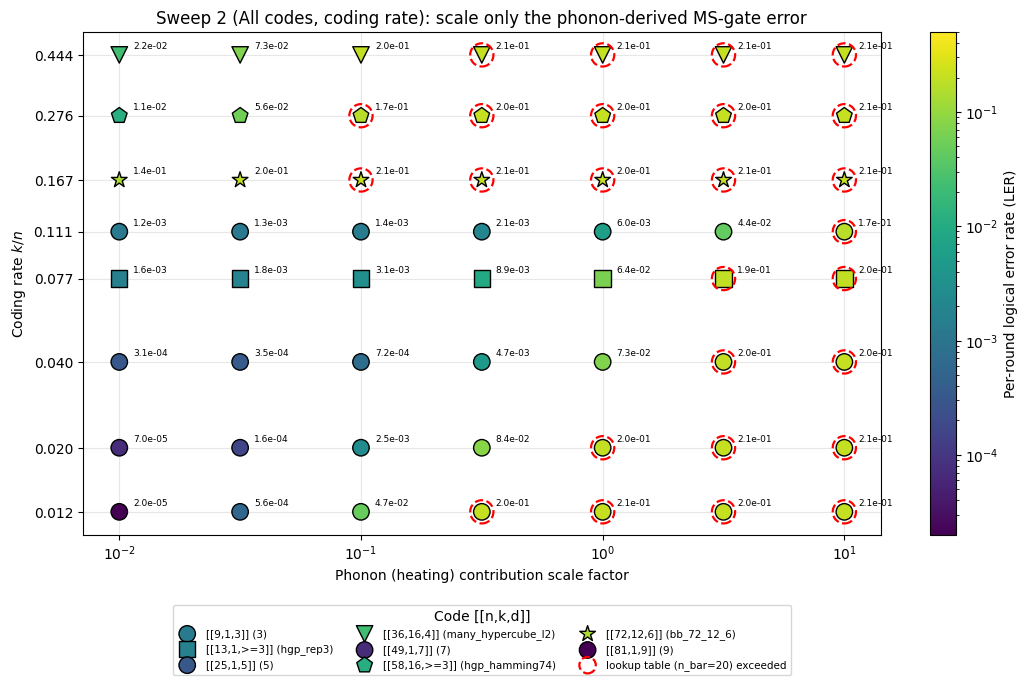

In [82]:
plot_cost_overview_combined(
    results_phonon_all,
    x_label='Phonon (heating) contribution scale factor',
    title='Sweep 2 (All codes, coding rate): scale only the phonon-derived MS-gate error',
    fname='sweep2_phonon_scale_all_rate.png',
    y_metric='rate',
)


### Sweep 3 (全符号, coding rate): フォノン数の上限 $n_{max}$ を仮定する

saved: results/ler_evaluation/sweep3_n_max_all_rate.png


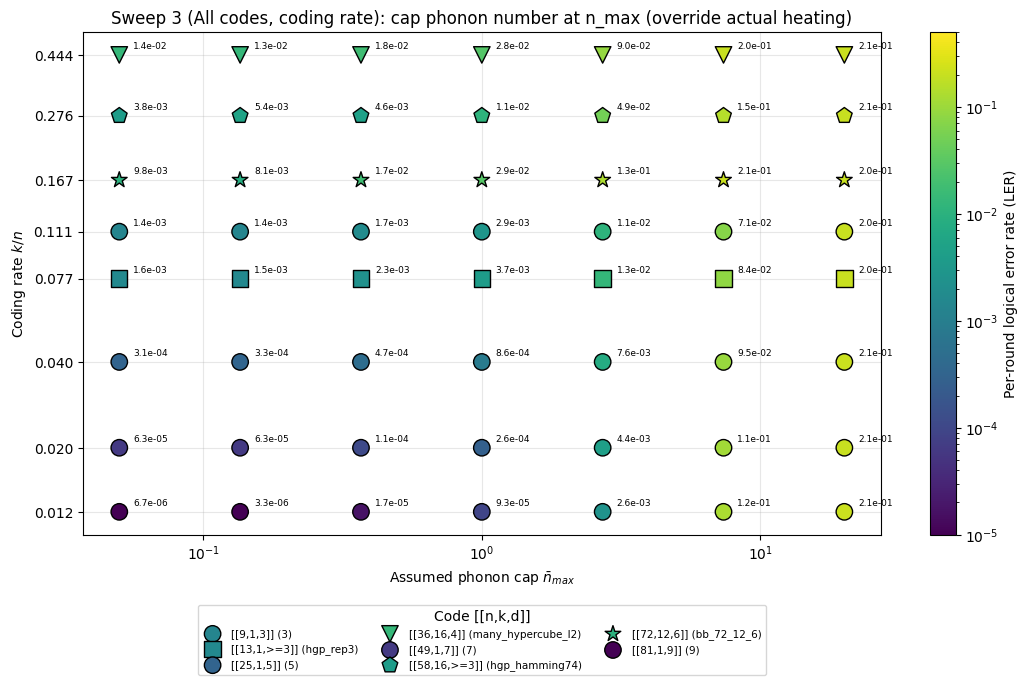

In [76]:
plot_cost_overview_combined(
    results_nmax_all,
    x_label=r'Assumed phonon cap $\bar{n}_{max}$',
    title='Sweep 3 (All codes, coding rate): cap phonon number at n_max (override actual heating)',
    fname='sweep3_n_max_all_rate.png',
    y_metric='rate',
)


## 今後の拡張

表面符号 ($[[d^2,1,d]]$), HGP ($[[13,1,3]]$ / $[[58,16,\ge 3]]$,
`experiments/generate_hgp_circuits.py`), BB ($[[72,12,6]]$ /
$[[144,12,12]]$, `experiments/generate_bb_circuits.py`), Many-hypercube
($[[36,16,4]]$, `experiments/generate_many_hypercube_circuits.py`) を
実装した。 他の符号 (Color code, $[[4,2,2]]$/Iceberg 等) も同様に追加していきたい。

新しい符号を追加する一般的な手順:
1. (CSS 符号なら) `src/css_code_utils.py` の
   `css_stabilizers`/`build_css_stim_circuit`/`save_css_circuit_module` を
   再利用して `circuits/<name>.py` を生成 (符号固有の Hx/Hz/logical 取得部分
   だけ差し替える — HGP は自前の `hgp_check_matrices`、 BB は
   `qldpc.codes.BBCode`、 Many-hypercube は既存 JSON をそのまま読み込み)
2. `compile_css_code(name, rounds)` (全符号共通の汎用関数) で
   `CODE_CACHE` に追加するだけで、 `build_noisy_circuit` / `run_sweep` /
   `plot_cost_overview` はそのまま再利用できる
3. $k>1$ の符号は `recompile_multi_round` が単一 observable しか張れない
   ため、 代表 1 個の logical Z だけを追う (HGP/BB/Many-hypercube と同じ制約)
4. MWPM (pymatching) が decompose できない non-local な符号は
   `simulate_p_L` が自動的に BP+OSD (`ldpc.BpOsdDecoder`) にフォールバック
   する (HGP の `hgp_hamming74`, BB で確認済み)。 **Many-hypercube
   (`many_hypercube_l2`) は意外にも MWPM がそのまま通る** (weight-12
   stabilizer はあるが n=36 と小さく decompose に失敗しない) — フォール
   バックせず通常の pymatching 経路 (= SHOTS をフルで使える、 高速) で
   動くことを実測確認済み。